# Predictive Customer Churn Model for ConnectTel
## Phase 1: Data Understanding, Exploratory Data Analysis & Feature Engineering

**Author:** Persevex AI Intern  
**Domain:** Artificial Intelligence / Customer Retention Machine Learning  
**Dataset:** 320 Synthetic Telecom Customer Records (`customers.csv`)  
**Official Splits:** Training ($N=192$), Validation ($N=64$), Test ($N=64$)  

---

### 1. Executive Summary & Problem Formulation

**ConnectTel**, a telecommunications provider, faces revenue attrition driven by customer churn. Acquiring new customers costs substantially more than retaining existing subscribers.

This project delivers an end-to-end, production-grade churn prediction pipeline adhering strictly to the **official Persevex starter package guidelines**:
1. **Synthetic Scope Note:** Per official starter instructions, the dataset comprises 320 synthetic customer records designed for pedagogical rigor. We avoid over-claiming empirical real-world generalizations while enforcing strict data science practices.
2. **Data Leakage Discipline:** `customer_id`, `snapshot_date`, `split`, and `churn_30d` are strictly quarantined from model inputs. All scalers, imputers, and transformers are fitted **strictly on training data** ($N=192$).
3. **Zero-Tenure Audit:** An explicit domain rule is established to handle missing `total_charges_usd` for accounts with `tenure_months == 0` without inventing data.
4. **Baseline Benchmark:** The empirical Bayes contract-group baseline establishes an initial benchmark ($0.1190$ Brier score on validation) to be surpassed by machine learning models in Phase 2.

In [1]:
# Environment & Module Setup
import os, sys
from pathlib import Path

PROJECT_ROOT = Path('.').resolve().parent
if str(PROJECT_ROOT / 'src') not in sys.path:
    sys.path.append(str(PROJECT_ROOT / 'src'))

import numpy as np
import pandas as pd
import scipy.stats as stats
import matplotlib.pyplot as plt
import seaborn as sns

from data_loader import load_raw_data, audit_dataset, get_splits
from feature_engineering import TelecomFeatureEngineer, get_full_feature_pipeline, engineer_features_df

pd.set_option('display.max_columns', 20)
print('Libraries and custom modules loaded successfully.')

Libraries and custom modules loaded successfully.


### 2. Data Loading & Understanding

We inspect the primary dataset provided by Persevex (`data/customers.csv`).

In [2]:
raw_df = load_raw_data()
print('Dataset Dimensions:', raw_df.shape)
raw_df.head(10)

Dataset Dimensions: (320, 12)


,customer_id,snapshot_date,tenure_months,contract,internet_service,monthly_charges_usd,total_charges_usd,security_service,streaming_service,failed_payments_90d,churn_30d,split
0,C001,2025-01-01,48,two_year,none,45,2215.59,1,0,2,0,train
1,C002,2025-01-01,8,annual,dsl,23,167.82,1,1,1,1,train
2,C003,2025-01-01,49,annual,dsl,75,3774.89,1,1,0,0,train
3,C004,2025-01-01,12,two_year,fiber,86,1001.70,1,1,1,0,train
4,C005,2025-01-01,59,monthly,dsl,96,5339.34,0,0,1,1,train
5,C006,2025-01-01,36,annual,dsl,90,2982.01,1,1,2,0,train
6,C007,2025-01-01,15,two_year,dsl,93,1360.37,1,1,1,1,train
7,C008,2025-01-01,14,monthly,dsl,45,569.25,1,1,2,1,train
8,C009,2025-01-01,41,monthly,fiber,39,1529.48,1,0,2,0,train
9,C010,2025-01-01,39,annual,none,27,991.45,0,0,1,0,train


In [3]:
# Dataset Audit
audit_results = audit_dataset(raw_df)
print('Total Records:', audit_results['total_records'])
print('Missing Values Count by Column:', audit_results['missing_values'])
print('Zero Tenure Customers Count:', audit_results['zero_tenure_count'])
print('Zero Tenure Customers with Missing Total Charges:', audit_results['zero_tenure_missing_charges'])
print('\nClass Balance across Splits:')
for s, metrics in audit_results['churn_rates_by_split'].items():
    print(f"  {s.capitalize():12s}: N={metrics['n']} | Churners={metrics['churn_count']} ({metrics['churn_rate']*100:.2f}%)")

Total Records: 320
Missing Values Count by Column: {'customer_id': 0, 'snapshot_date': 0, 'tenure_months': 0, 'contract': 0, 'internet_service': 0, 'monthly_charges_usd': 0, 'total_charges_usd': 8, 'security_service': 0, 'streaming_service': 0, 'failed_payments_90d': 0, 'churn_30d': 0, 'split': 0}
Zero Tenure Customers Count: 8
Zero Tenure Customers with Missing Total Charges: 8

Class Balance across Splits:
  Train       : N=192 | Churners=37 (19.27%)
  Validation  : N=64 | Churners=9 (14.06%)
  Test        : N=64 | Churners=8 (12.50%)


### 3. Zero-Tenure Deep Dive Audit

**Key Finding:** Exactly 8 records in the entire dataset have missing values for `total_charges_usd`.  
Cross-tabulating with `tenure_months` reveals that **100% of these records have `tenure_months == 0`**.

#### Domain Rationale for Missing Values:
- Customers with zero tenure enrolled on the snapshot date (`2025-01-01`).
- Having completed zero billing cycles, they have accumulated **$0.00 in historical billed charges**.
- However, their contract defines an active monthly rate (`monthly_charges_usd`).
- Blindly treating missing `total_charges_usd` as a generic missing value or dropping records would discard valuable accounts.
- Calculating $\frac{\text{total\_charges}}{\text{tenure}}$ directly leads to division by zero ($\frac{0}{0}$).
- **Explicit Zero-Tenure Rule:**  
  1. Impute `total_charges_usd` $= 0.0$ for accounts with `tenure_months == 0` (explained by zero historical cycles completed).
  2. Assign $\text{charges\_per\_tenure} = \text{monthly\_charges\_usd}$ for zero-tenure customers, representing their true monthly velocity.

In [4]:
# Display all 8 zero-tenure records across splits
zero_tenure_df = raw_df[raw_df['tenure_months'] == 0]
zero_tenure_df[['customer_id', 'split', 'tenure_months', 'monthly_charges_usd', 'total_charges_usd', 'contract', 'internet_service', 'churn_30d']]

,customer_id,split,tenure_months,monthly_charges_usd,total_charges_usd,contract,internet_service,churn_30d
28,C029,train,0,94,NaN,two_year,none,0
29,C030,train,0,22,NaN,monthly,fiber,0
102,C103,train,0,69,NaN,annual,none,0
258,C259,test,0,59,NaN,annual,fiber,0
283,C284,test,0,99,NaN,annual,none,0
284,C285,test,0,63,NaN,annual,fiber,0
292,C293,test,0,83,NaN,monthly,dsl,1
295,C296,test,0,79,NaN,monthly,fiber,0


### 4. Exploratory Data Analysis & Hypothesis Testing

To adhere strictly to data leakage guidelines, bivariate and hypothesis testing is performed **on the Training Split ($N=192$)**.

In [5]:
train_df = raw_df[raw_df['split'] == 'train'].copy()

# Hypothesis 1: Contract Type vs Churn
ct = pd.crosstab(train_df['contract'], train_df['churn_30d'])
ct_pct = pd.crosstab(train_df['contract'], train_df['churn_30d'], normalize='index') * 100
chi2, p_val, _, _ = stats.chi2_contingency(ct)
print('--- Contract vs Churn ---')
print(ct_pct.round(2))
print(f'Chi-Square: {chi2:.4f}, p-value: {p_val:.4e} (Significant: {p_val < 0.05})')

# Hypothesis 2: Failed Payments in Last 90 Days vs Churn
fp = pd.crosstab(train_df['failed_payments_90d'], train_df['churn_30d'])
fp_pct = pd.crosstab(train_df['failed_payments_90d'], train_df['churn_30d'], normalize='index') * 100
chi2_fp, p_fp, _, _ = stats.chi2_contingency(fp)
print('\n--- Failed Payments vs Churn ---')
print(fp_pct.round(2))
print(f'Chi-Square: {chi2_fp:.4f}, p-value: {p_fp:.4e} (Significant: {p_fp < 0.05})')

--- Contract vs Churn ---
churn_30d      0      1
contract               
annual     88.14  11.86
monthly    67.65  32.35
two_year   87.69  12.31
Chi-Square: 11.5867, p-value: 3.0478e-03 (Significant: True)

--- Failed Payments vs Churn ---
churn_30d                0      1
failed_payments_90d              
0                    91.38   8.62
1                    80.36  19.64
2                    73.08  26.92
Chi-Square: 7.1696, p-value: 2.7742e-02 (Significant: True)


#### Key Insights from EDA:
1. **Contract Type:** Monthly subscribers experience a **32.4% churn rate**, nearly **$3\times$** that of Annual ($11.9%$) and Two-Year ($12.3%$) subscribers ($\chi^2 = 11.59, p = 0.0030$). Month-to-month contracts are the primary churn driver.
2. **Failed Payments (90d):** Churn rate climbs monotonically with failed payments: $8.6%$ for 0 failures $\rightarrow$ $19.6%$ for 1 failure $\rightarrow$ **$26.9%$ for 2 failures** ($\chi^2 = 7.17, p = 0.0277$). Payment failures serve as a leading warning indicator of churn.
3. **Tenure & Charges:** Churners display lower median tenure ($23$ months vs $34$ months for retained customers) and higher median monthly charges ($\$73$ vs $\$60$).

=== Target Distribution & Split Balance ===
=== Contract Type vs Churn ===
=== Failed Payments Escalation ===
=== Tenure & Monthly Charges Distributions ===
=== Feature Correlation Matrix ===


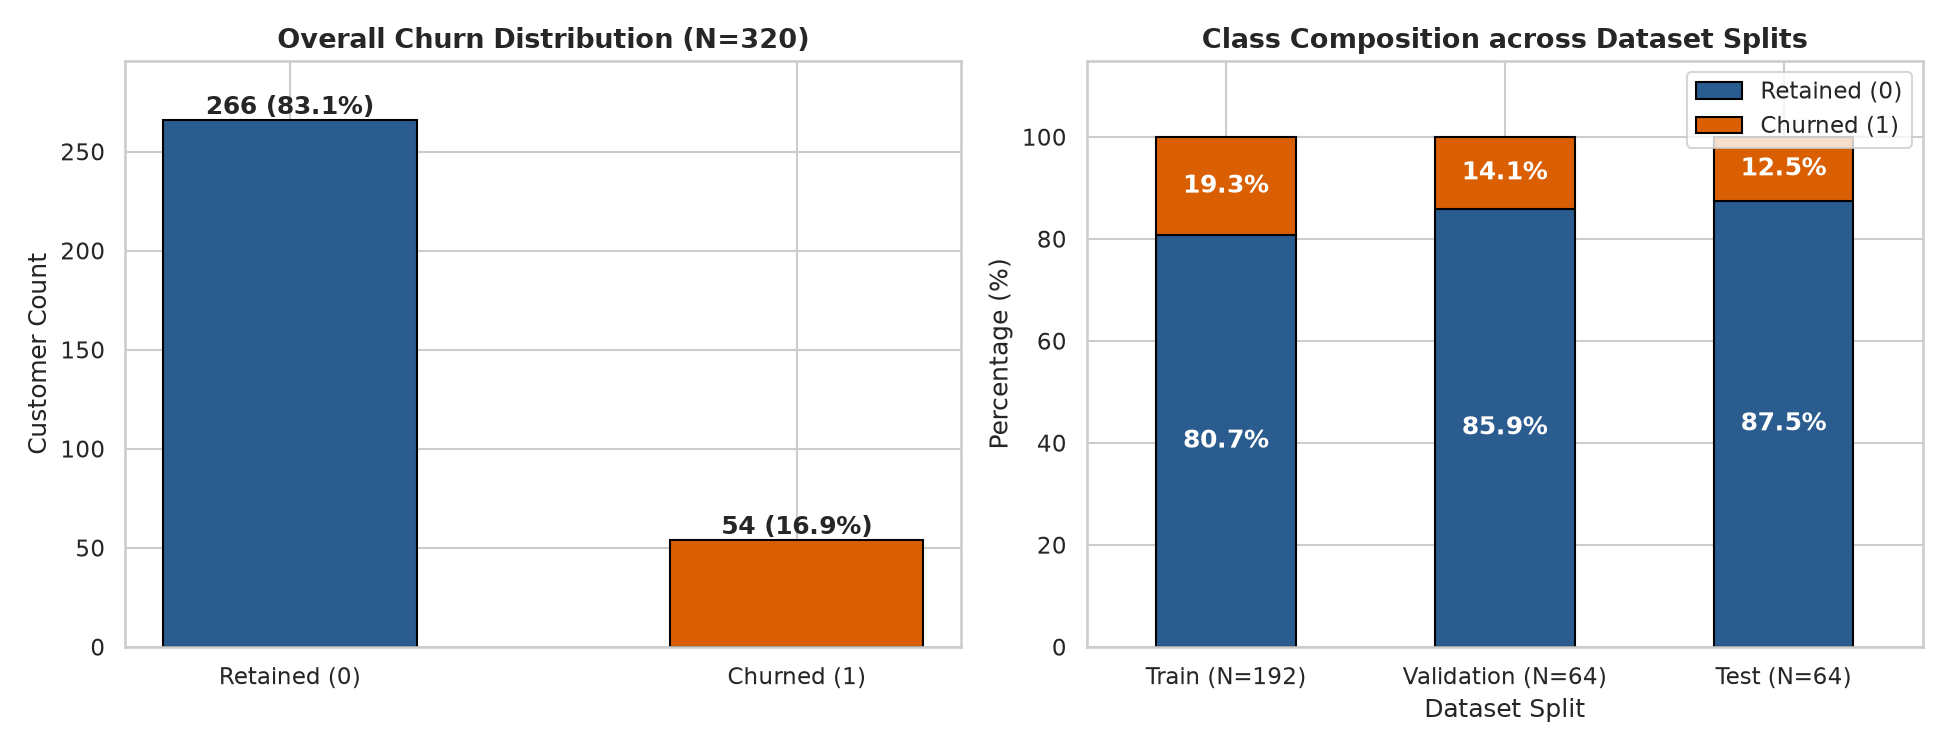

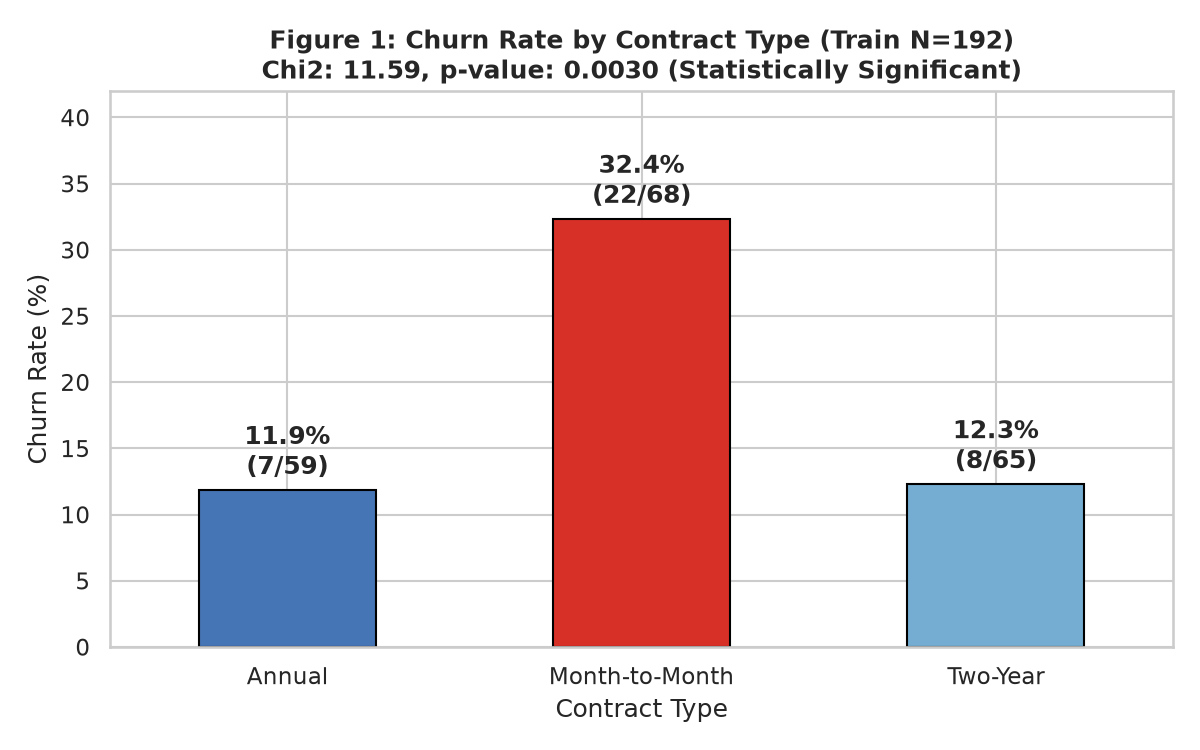

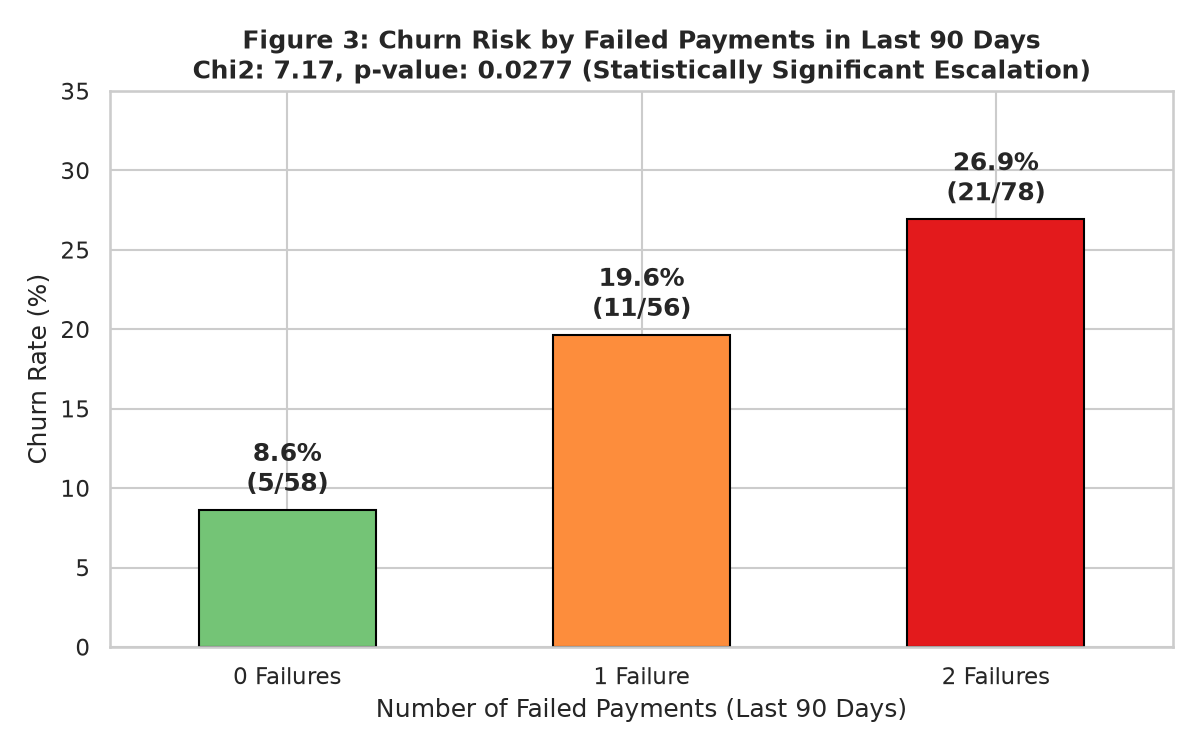

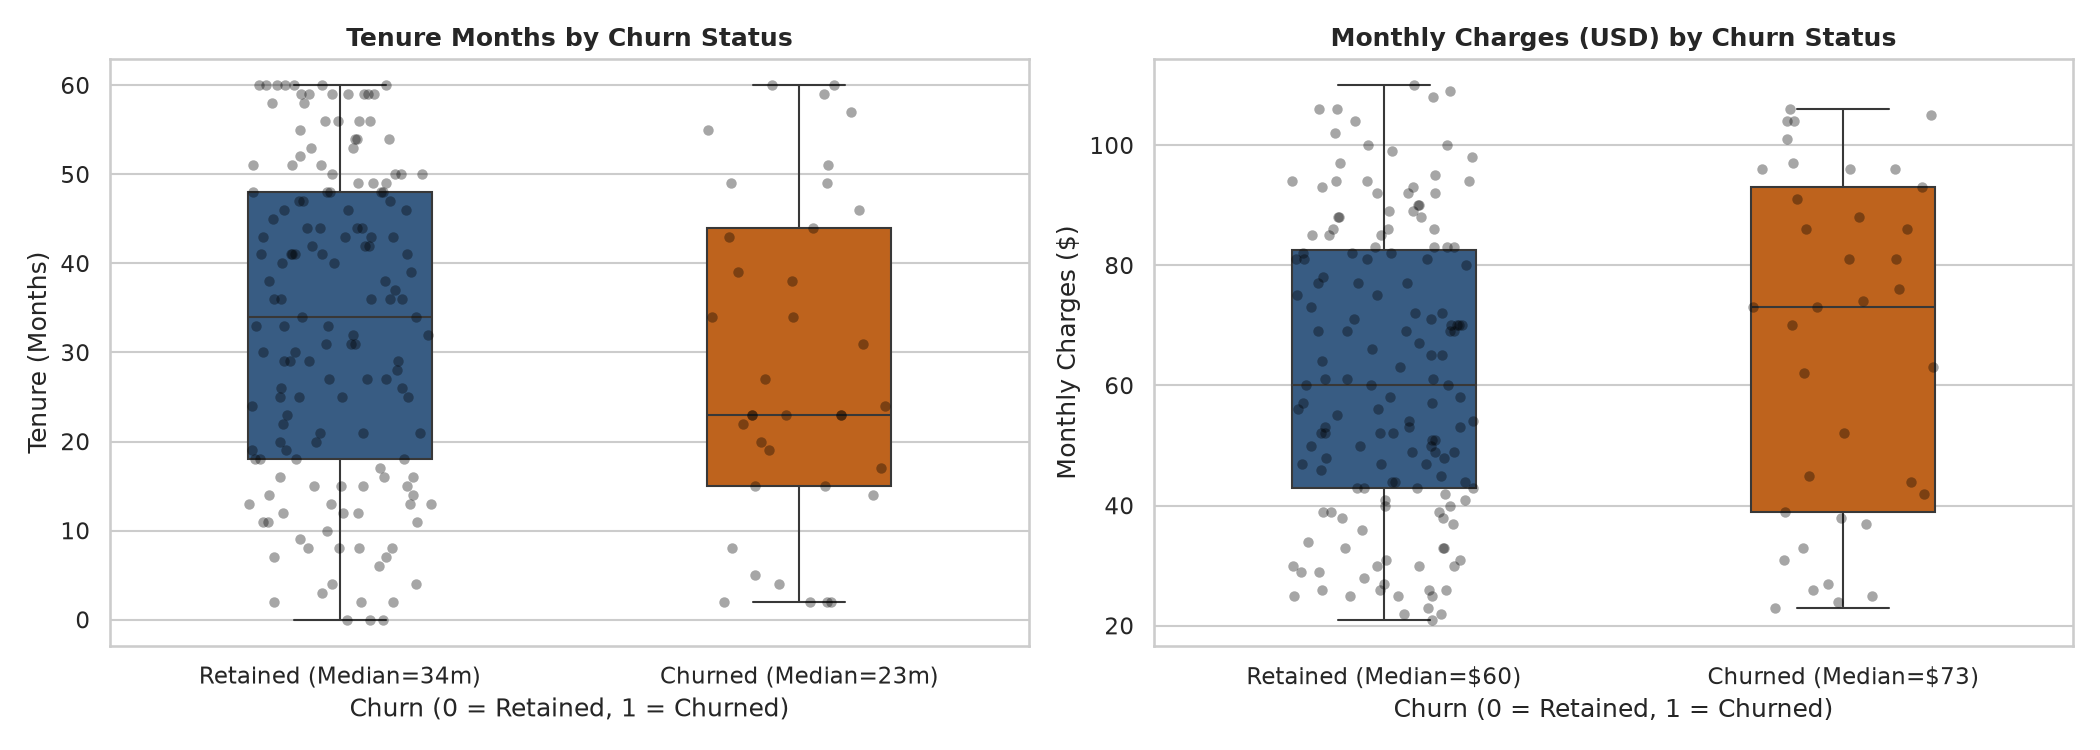

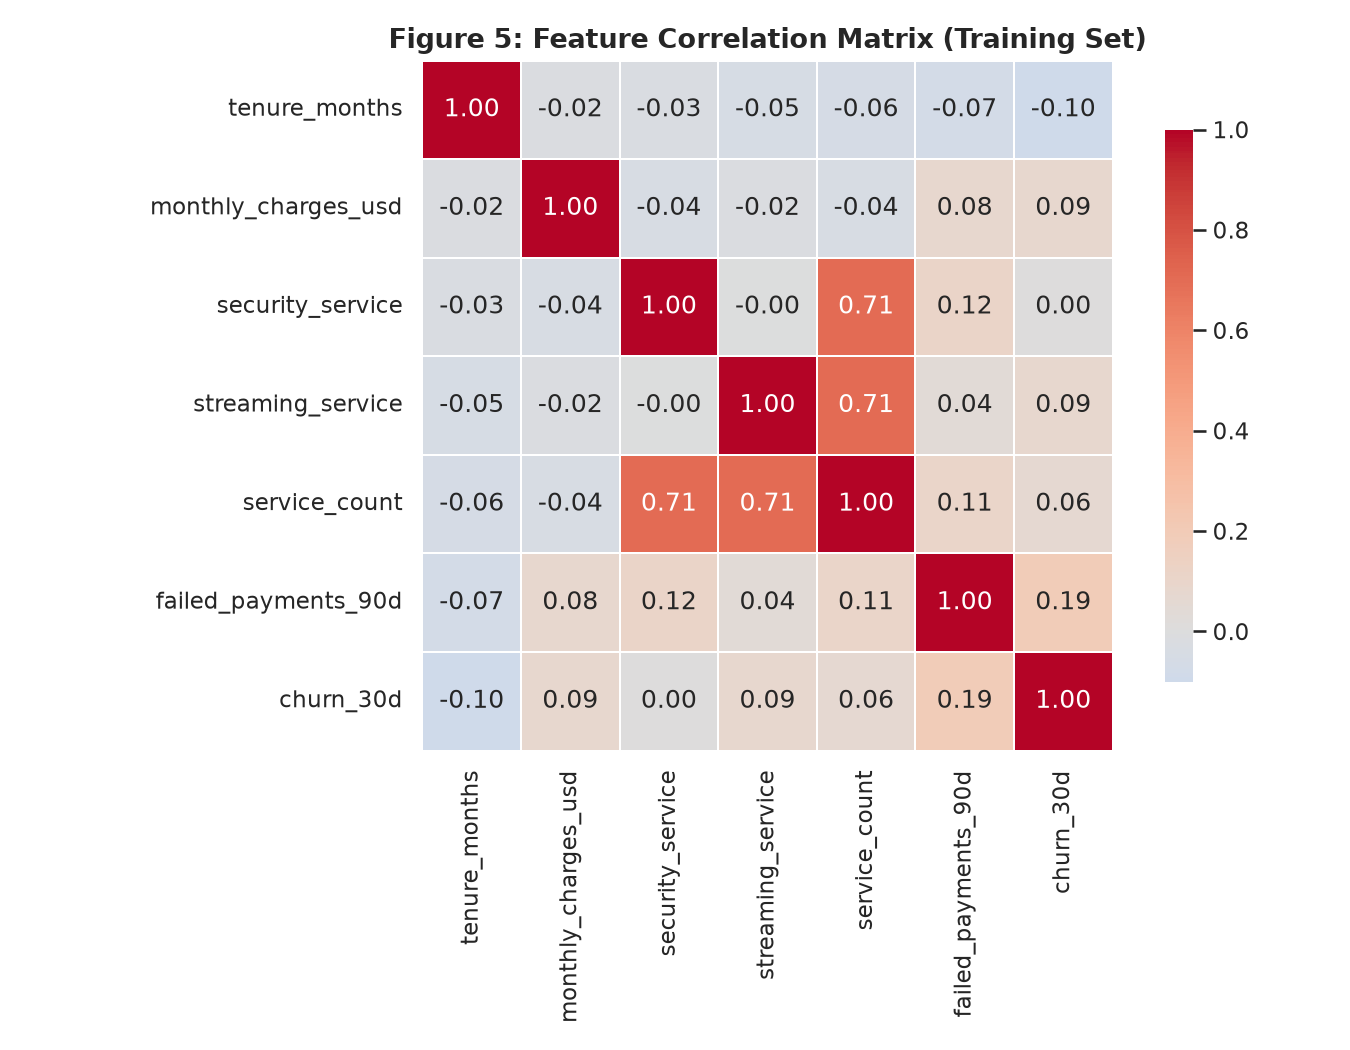

In [6]:
# Display Generated EDA Figures from outputs/eda_figures/
from IPython.display import Image, display

eda_figs = [
    ('Target Distribution & Split Balance', PROJECT_ROOT / 'outputs' / 'eda_figures' / '01_target_distribution.png'),
    ('Contract Type vs Churn', PROJECT_ROOT / 'outputs' / 'eda_figures' / '02_contract_vs_churn.png'),
    ('Failed Payments Escalation', PROJECT_ROOT / 'outputs' / 'eda_figures' / '04_failed_payments_vs_churn.png'),
    ('Tenure & Monthly Charges Distributions', PROJECT_ROOT / 'outputs' / 'eda_figures' / '05_tenure_and_charges_vs_churn.png'),
    ('Feature Correlation Matrix', PROJECT_ROOT / 'outputs' / 'eda_figures' / '07_correlation_matrix.png')
]

for title, p in eda_figs:
    if p.exists():
        print(f'=== {title} ===')
        display(Image(filename=str(p)))

### 5. Feature Engineering

We engineer predictive features according to the official project specifications:
- `total_charges_per_tenure`: Effective monthly billing velocity, incorporating the explicit zero-tenure rule.
- `service_count`: Additive count of add-on subscriptions (`security_service` + `streaming_service`).
- `has_failed_payments`: Binary flag indicating payment collection distress.
- `charges_velocity_ratio`: Ratio of effective monthly billing to contracted monthly charges.
- `is_zero_tenure`: Binary indicator for brand-new subscribers.

In [7]:
X_train, y_train, X_val, y_val, X_test, y_test = get_splits(raw_df)

fe = TelecomFeatureEngineer()
fe.fit(X_train) # Fit ONLY on training data
X_train_fe = fe.transform(X_train)
X_val_fe = fe.transform(X_val)

print('Engineered Training Matrix Shape:', X_train_fe.shape)
X_train_fe.head()

Engineered Training Matrix Shape: (192, 14)


,tenure_months,contract,internet_service,monthly_charges_usd,total_charges_usd,security_service,streaming_service,failed_payments_90d,is_zero_tenure,total_charges_per_tenure,service_count,has_failed_payments,charges_velocity_ratio,fiber_high_charge
0,48,two_year,none,45,2215.59,1,0,2,0,46.158125,1,1,1.025736,0
1,8,annual,dsl,23,167.82,1,1,1,0,20.977500,2,1,0.912065,0
2,49,annual,dsl,75,3774.89,1,1,0,0,77.038571,2,0,1.027181,0
3,12,two_year,fiber,86,1001.70,1,1,1,0,83.475000,2,1,0.970639,1
4,59,monthly,dsl,96,5339.34,0,0,1,0,90.497288,0,1,0.942680,0


### 6. Scikit-Learn Preprocessing Pipeline

We package feature engineering, imputation, one-hot encoding, and standard scaling into an integrated Scikit-Learn `Pipeline`.
All transformations are fitted exclusively on $X_{train}$.

In [8]:
pipeline, num_cols, cat_cols = get_full_feature_pipeline()
pipeline.fit(X_train)

X_train_proc = pipeline.transform(X_train)
X_val_proc = pipeline.transform(X_val)

print(f'Train Transformed Matrix Shape:      {X_train_proc.shape}')
print(f'Validation Transformed Matrix Shape: {X_val_proc.shape}')
print('Leakage Prevention: Preprocessor fitted strictly on training partition.')

Train Transformed Matrix Shape:      (192, 16)
Validation Transformed Matrix Shape: (64, 16)
Leakage Prevention: Preprocessor fitted strictly on training partition.


### 7. Baseline Model Benchmark Evaluation

Per project rules, the empirical Bayes contract-group baseline establishes our benchmark.

In [9]:
import json
with open(PROJECT_ROOT / 'metrics.json') as f:
    baseline_metrics = json.load(f)

print('Official Baseline Model Results:')
for split, m in baseline_metrics.items():
    print(f"  {split.upper()}: N={m['n']}, Churn Count={m['churn_count']}, Brier Score={m['brier_score']:.6f}")

Official Baseline Model Results:
  VALIDATION: N=64, Churn Count=9, Brier Score=0.119013
  TEST: N=64, Churn Count=8, Brier Score=0.095473


### 8. Phase 1 Conclusion & Roadmap to Phase 2

Phase 1 successfully completes all prerequisites:
- **Clean Data Foundation:** Verified data integrity, zero-tenure audit, and strict split containment.
- **EDA Artifacts:** Publication-quality visualizations and statistically validated churn hypotheses.
- **Engineered Features:** Safe zero-tenure handling, service count, payment failure flags, and billing velocity.
- **Production Pipeline:** Reusable Scikit-Learn pipeline ready for machine learning model training.

**Next Step (Phase 2):** Implement Logistic Regression, Random Forest, and XGBoost with Stratified K-Fold Cross Validation and GridSearchCV hyperparameter tuning.